<a href="https://colab.research.google.com/github/siriscent7/CS228_project/blob/main/two_tier_face_verification_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Two-tier face verification: FP32 vs INT8 + selective FP32 re-check
**Runtime:** Runtime → Change runtime type → Python 3, hardware accelerator = **None (CPU)**. Standard RAM is enough.
Do not use GPU/TPU: the code uses ONNX Runtime's CPU provider and the INT8 latency numbers are CPU-specific.
Put `w600k_r50.onnx` and `lfw.bin` in `PROJECT_DIR` on Google Drive (set below). All outputs are saved there too,
so a runtime restart loses nothing. Run the cells top to bottom.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q onnx onnxruntime pillow pandas matplotlib scikit-learn

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
import io, json, os, pickle, platform, shutil, subprocess, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import roc_auc_score
import onnxruntime as ort
ort.set_default_logger_severity(3)   # silence harmless "expected shape {1,512}" warnings

# ---------------- configuration ----------------
PROJECT_DIR  = Path("/content/drive/MyDrive/CS228")
FP32_PATH    = PROJECT_DIR / "w600k_r50.onnx"
LFW_BIN_PATH = PROJECT_DIR / "lfw.bin"
INT8_PATH    = PROJECT_DIR / "w600k_r50_int8.onnx"      # the INT8 model chosen by the quantization cell
OUT_DIR      = PROJECT_DIR / "results"; OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_PATH   = OUT_DIR / "embeddings.npz"
FAR_TARGET   = 0.01                      # threshold calibrated so FAR = 1% on the calibration split
BUDGETS = (0.005, 0.01, 0.02, 0.03, 0.05, 0.10, 0.20)  # fraction of pairs sent to the FP32 tier
FLIP_RECALL  = 0.95                      # alternative gate: catch 95% of INT8/FP32 disagreements
N_SPLITS     = 10                        # repeated random 50/50 calibration/test splits
CALIB_N      = 100                       # images used to calibrate INT8 activation ranges
CHECK_N      = 16                        # held-out images used to compare INT8 vs FP32 embeddings
N_PAIRS      = None                     # e.g. 600 for a quick smoke test; None = all 6000
FORCE_REQUANT = False                    # True = redo quantization even if INT8_PATH already exists
THREADS      = 0                         # 0 = ORT default (all cores)
SEED         = 0
mb = lambda p: os.path.getsize(p) / 1e6

for p in (FP32_PATH, LFW_BIN_PATH):
    assert os.path.exists(p), f"Missing file: {p}"
print("ORT", ort.__version__, "| providers:", ort.get_available_providers())
print(subprocess.run("lscpu | grep -E 'Model name|^CPU\\(s\\)'", shell=True, capture_output=True, text=True).stdout)
flags = open("/proc/cpuinfo").read()
print("AVX2:", "avx2" in flags, "| AVX512:", "avx512f" in flags, "| VNNI:", "vnni" in flags)


ORT 1.31.0 | providers: ['AzureExecutionProvider', 'CPUExecutionProvider']
CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz

AVX2: True | AVX512: False | VNNI: False


In [22]:
# ---------------- data ----------------
def load_lfw_bin(path, n_pairs=None):
    with open(path, "rb") as f:
        bins, issame = pickle.load(f, encoding="bytes")
    if n_pairs:                                    # keep a balanced subset for smoke tests
        issame = np.asarray(issame, dtype=int)
        rng = np.random.RandomState(SEED)
        idx = np.sort(np.concatenate([rng.choice(np.where(issame == c)[0], n_pairs // 2, replace=False) for c in (0, 1)]))
        bins = [bins[2 * i + j] for i in idx for j in (0, 1)]
        issame = issame[idx]
    imgs = [np.asarray(Image.open(io.BytesIO(b)).convert("RGB")) for b in bins]
    a, b = np.stack(imgs[0::2]), np.stack(imgs[1::2])
    assert a.shape[1:3] == (112, 112), a.shape
    return a, b, np.asarray(issame, dtype=int)

img_a, img_b, labels = load_lfw_bin(LFW_BIN_PATH, N_PAIRS)
print(img_a.shape, "pairs; positives:", labels.sum(), "negatives:", (labels == 0).sum())

(6000, 112, 112, 3) pairs; positives: 3000 negatives: 3000


In [23]:
# ---------------- embedder (ONNX Runtime, CPU) ----------------
class OrtEmbedder:
    def __init__(self, path, threads=0):
        opts = ort.SessionOptions()
        if threads: opts.intra_op_num_threads = threads
        self.sess = ort.InferenceSession(str(path), opts, providers=["CPUExecutionProvider"])
        inp = self.sess.get_inputs()[0]
        self.name = inp.name
        self.fixed = inp.shape[0] if isinstance(inp.shape[0], int) else None   # fixed batch size, if any

    @staticmethod
    def prep(images_u8):                              # RGB uint8 NHWC -> float NCHW in [-1, 1]
        x = (images_u8.astype(np.float32) - 127.5) / 127.5
        return np.ascontiguousarray(x.transpose(0, 3, 1, 2))

    def embed(self, images_u8, batch_size=32):
        bs = self.fixed or batch_size
        out = []
        for i in range(0, len(images_u8), bs):
            chunk = images_u8[i:i + bs]; n = len(chunk)
            if self.fixed and n < bs:                 # pad the last batch for fixed-batch models
                chunk = np.concatenate([chunk, np.repeat(chunk[-1:], bs - n, axis=0)])
            out.append(self.sess.run(None, {self.name: self.prep(chunk)})[0][:n])
        e = np.concatenate(out)
        return e / np.linalg.norm(e, axis=1, keepdims=True)

fp32 = OrtEmbedder(FP32_PATH, THREADS)
print("FP32 input:", fp32.sess.get_inputs()[0].shape, "| fixed batch:", fp32.fixed)

FP32 input: ['None', 3, 112, 112] | fixed batch: None


In [24]:
# ---------------- shared split helpers ----------------
def stratified_splits(labels, n_splits, seed=SEED):
    """Repeated stratified 50/50 calibration/test splits over PAIRS."""
    rng = np.random.RandomState(seed)
    for _ in range(n_splits):
        cal, tst = [], []
        for c in (0, 1):
            idx = rng.permutation(np.where(labels == c)[0])
            h = len(idx) // 2
            cal.append(idx[:h]); tst.append(idx[h:])
        yield np.sort(np.concatenate(cal)), np.sort(np.concatenate(tst))

splits = list(stratified_splits(labels, N_SPLITS))

In [25]:
# ---------------- INT8 quantization: opset fix, diagnostics, variant sweep, selection ----------------
import onnx
from onnx import numpy_helper, version_converter
from onnxruntime.quantization import (quantize_static, CalibrationDataReader,
                                      QuantFormat, QuantType, CalibrationMethod)

class FaceCalibReader(CalibrationDataReader):
    """Feeds real face crops so ORT can estimate activation ranges."""
    def __init__(self, images_u8, input_name, batch):
        self.batches = iter([{input_name: OrtEmbedder.prep(images_u8[i:i + batch])}
                             for i in range(0, len(images_u8) - batch + 1, batch)])
    def get_next(self): return next(self.batches, None)

def loads_ok(p):
    try: ort.InferenceSession(str(p), providers=["CPUExecutionProvider"]); return True
    except Exception as e: print("Cannot load", Path(p).name, "->", str(e)[:120]); return False

REPORT_PATH = OUT_DIR / "quant_report.json"
if INT8_PATH.exists() and REPORT_PATH.exists() and not FORCE_REQUANT and loads_ok(INT8_PATH):
    print("Reusing existing INT8 model:", json.load(open(REPORT_PATH))["chosen"])
else:
    # calibration + held-out check images come from the calibration side of split 0: never test pairs
    cal0 = splits[0][0]
    pool = np.concatenate([img_a[cal0], img_b[cal0]])
    perm = np.random.RandomState(SEED).permutation(len(pool))
    calib_imgs, check_imgs = pool[perm[:CALIB_N]], pool[perm[CALIB_N:CALIB_N + CHECK_N]]
    ref_emb = fp32.embed(check_imgs)
    eval_cos = lambda p: np.sum(ref_emb * OrtEmbedder(p, THREADS).embed(check_imgs), axis=1)

    # per-channel quantization needs opset >= 13; the InsightFace model is opset 11
    SRC13 = PROJECT_DIR / "w600k_r50_opset13.onnx"
    if not SRC13.exists():
        onnx.save(version_converter.convert_version(onnx.load(str(FP32_PATH)), 13), str(SRC13))
    print("opset-13 model ready; opset-13 vs original FP32 cosine: %.5f" % eval_cos(SRC13).mean())

    # Test A: weight-only per-channel int8 (simulated in numpy, activations stay FP32)
    m = onnx.load(str(SRC13)); inits = {i.name: i for i in m.graph.initializer}; n_q = 0
    for n in m.graph.node:
        if n.op_type not in ("Conv", "Gemm", "MatMul") or len(n.input) < 2 or n.input[1] not in inits: continue
        w = numpy_helper.to_array(inits[n.input[1]]).astype(np.float32)
        if n.op_type == "Conv": ax = 0
        elif n.op_type == "MatMul": ax = w.ndim - 1
        else: ax = 0 if next((a.i for a in n.attribute if a.name == "transB"), 0) == 1 else 1
        wm = np.moveaxis(w, ax, 0); flat = wm.reshape(wm.shape[0], -1)
        scale = np.maximum(np.abs(flat).max(1, keepdims=True) / 127.0, 1e-12)
        dq = (np.clip(np.round(flat / scale), -127, 127) * scale).reshape(wm.shape)
        inits[n.input[1]].CopyFrom(numpy_helper.from_array(np.moveaxis(dq, 0, ax).astype(np.float32), n.input[1])); n_q += 1
    WQ = PROJECT_DIR / "w600k_r50_weightonly_int8sim.onnx"; onnx.save(m, str(WQ))
    cw = eval_cos(WQ)
    print(f"Test A  weight-only int8 ({n_q} layers): mean cos {cw.mean():.4f}, min {cw.min():.4f}")

    # Test B: full static quantization (QDQ), several variants; reduce_range guards against
    # 16-bit saturation in u8*s8 kernels on CPUs without VNNI (typical Colab Xeon)
    VARIANTS = {   # name: (weight type, activation type, reduce_range)
        "rr_w8_au8": (QuantType.QInt8,  QuantType.QUInt8, True),
        "rr_w8_a8":  (QuantType.QInt8,  QuantType.QInt8,  True),
        "w_u8_a_u8": (QuantType.QUInt8, QuantType.QUInt8, False),
    }
    results = {}
    for name, (wt, at, rr) in VARIANTS.items():
        path = PROJECT_DIR / f"w600k_r50_int8_{name}.onnx"; t0 = time.time()
        try:
            quantize_static(str(SRC13), str(path), FaceCalibReader(calib_imgs, fp32.name, fp32.fixed or 1),
                            quant_format=QuantFormat.QDQ, per_channel=True, reduce_range=rr,
                            weight_type=wt, activation_type=at,
                            op_types_to_quantize=["Conv", "MatMul", "Gemm"],
                            calibrate_method=CalibrationMethod.MinMax)
            c = eval_cos(path)
            results[name] = dict(path=str(path), mean_cos=float(c.mean()), min_cos=float(c.min()), size_mb=mb(path))
        except Exception as e:
            print(f"{name} failed: {str(e)[:200]}")
        print(f"Test B  {name}: {time.time() - t0:.0f}s -> {results.get(name)}")

    assert results, "All quantization variants failed; see messages above"
    res = pd.DataFrame(results).T.sort_values("mean_cos", ascending=False)
    print(res.drop(columns="path").round(4).to_string())
    best = res.index[0]
    shutil.copy(res.loc[best, "path"], INT8_PATH)
    json.dump(dict(chosen=best, weight_only_mean_cos=float(cw.mean()), variants=results,
                   check_images=CHECK_N, calib_images=CALIB_N), open(REPORT_PATH, "w"), indent=2)
    print(f"\nChosen: {best} -> {INT8_PATH.name}")
    if res.loc[best, "mean_cos"] < 0.90:
        print("WARNING: best INT8 variant is still far from FP32 (mean cosine < 0.90). "
              "Report this honestly as a quantization-quality finding or try mixed precision.")

int8 = OrtEmbedder(INT8_PATH, THREADS)
print(f"FP32 {mb(FP32_PATH):.1f} MB  ->  INT8 {mb(INT8_PATH):.1f} MB  ({mb(FP32_PATH)/mb(INT8_PATH):.1f}x smaller)")

Reusing existing INT8 model: w_u8_a_u8
FP32 174.4 MB  ->  INT8 44.0 MB  (4.0x smaller)


In [26]:
# ---------------- embeddings -> pair scores (cached; cache is invalidated when the INT8 model changes) ----------------
def pair_scores(model, a, b):
    ea, eb = model.embed(a), model.embed(b)
    return np.sum(ea * eb, axis=1)                     # cosine similarity (embeddings are L2-normalised)

int8_bytes = os.path.getsize(INT8_PATH)
use_cache = False
if CACHE_PATH.exists():
    z = np.load(CACHE_PATH)
    use_cache = ("int8_bytes" in z.files and int(z["int8_bytes"]) == int8_bytes
                 and z["labels"].shape == labels.shape and np.array_equal(z["labels"], labels))
if use_cache:
    s_fp32, s_int8 = z["s_fp32"], z["s_int8"]; print("Loaded cached scores")
else:
    t0 = time.time(); s_fp32 = pair_scores(fp32, img_a, img_b); print(f"FP32 scoring {time.time()-t0:.0f}s")
    t0 = time.time(); s_int8 = pair_scores(int8, img_a, img_b); print(f"INT8 scoring {time.time()-t0:.0f}s")
    np.savez(CACHE_PATH, s_fp32=s_fp32, s_int8=s_int8, labels=labels, int8_bytes=int8_bytes)

print("AUC  FP32: %.4f | INT8: %.4f" % (roc_auc_score(labels, s_fp32), roc_auc_score(labels, s_int8)))
print("Score correlation FP32 vs INT8: %.4f" % np.corrcoef(s_fp32, s_int8)[0, 1])

FP32 scoring 5279s
INT8 scoring 2444s
AUC  FP32: 0.9994 | INT8: 0.9994
Score correlation FP32 vs INT8: 0.9995


In [27]:
# ---------------- latency benchmark (measured, per pair = 2 images) ----------------
def bench(model, images, batch, reps=5, warmup=2):
    x = images[:batch]
    for _ in range(warmup): model.embed(x, batch)
    ts = []
    for _ in range(reps):
        t = time.perf_counter(); model.embed(x, batch); ts.append(time.perf_counter() - t)
    return float(np.median(ts)) / len(x) * 1000         # ms per image

lat = {}
for bsz in ([1] if fp32.fixed == 1 else [1, 32]):
    n = max(bsz, 16)
    lat[bsz] = {"fp32_ms_img": bench(fp32, img_a[:n], bsz), "int8_ms_img": bench(int8, img_a[:n], bsz)}
print(pd.DataFrame(lat).T.round(2))
LAT_BATCH = 1                                            # edge-style, one verification at a time
c1 = 2 * lat[LAT_BATCH]["int8_ms_img"]                   # INT8 cost per pair (ms)
c2 = 2 * lat[LAT_BATCH]["fp32_ms_img"]                   # FP32 cost per pair (ms)
print(f"c1 (INT8/pair) = {c1:.1f} ms | c2 (FP32/pair) = {c2:.1f} ms | break-even escalation e < {1 - c1/c2:.2f}")

    fp32_ms_img  int8_ms_img
1        393.62       193.45
32       424.50       189.53
c1 (INT8/pair) = 386.9 ms | c2 (FP32/pair) = 787.2 ms | break-even escalation e < 0.51


In [28]:
# ---------------- threshold, gate and two-tier logic ----------------
def tau_at_far(neg_scores, far):
    neg = np.sort(np.asarray(neg_scores))
    k = max(0, min(len(neg) - 1, int(np.ceil((1 - far) * len(neg)) - 1)))
    return float(neg[k])

def delta_for_budget(scores, tau, budget):
    return float(np.quantile(np.abs(np.asarray(scores) - tau), budget)) if budget > 0 else 0.0

def calibrate_delta_flip(s8, s32, t8, t32, recall):
    near = np.abs(s8 - t8); flip = (s8 >= t8) != (s32 >= t32)
    if not flip.any(): return 0.0
    v = np.sort(near[flip]); k = max(1, int(np.ceil(recall * flip.sum())))
    return float(v[min(k - 1, len(v) - 1)])

def two_tier(s8, s32, t8, t32, delta):
    esc = np.abs(s8 - t8) < delta                        # Tier-1 margin gate
    return np.where(esc, s32 >= t32, s8 >= t8), esc

def run_split(cal, tst, rng):
    y = labels[cal]
    t32 = tau_at_far(s_fp32[cal][y == 0], FAR_TARGET)
    t8  = tau_at_far(s_int8[cal][y == 0], FAR_TARGET)
    ref = s_fp32[tst] >= t32
    yt = labels[tst]; pos, neg = yt == 1, yt == 0
    rows = []
    def add(name, dec, esc):
        e = float(np.mean(esc))
        rows.append(dict(system=name, TAR=dec[pos].mean(), FAR=dec[neg].mean(),
                         accuracy=np.mean(dec == (yt == 1)), agreement_FP32=np.mean(dec == ref),
                         escalation=e, est_latency_ms=c1 + e * c2))
    add("FP32 (reference)", ref, np.ones(len(tst), bool))
    add("INT8 only", s_int8[tst] >= t8, np.zeros(len(tst), bool))
    for b in BUDGETS:
        d = delta_for_budget(s_int8[cal], t8, b)
        dec, esc = two_tier(s_int8[tst], s_fp32[tst], t8, t32, d); add(f"Two-tier (margin) b={b:.2f}", dec, esc)
        # control: escalate the same fraction of pairs but chosen at random (does the margin gate matter?)
        resc = rng.random(len(tst)) < esc.mean()
        add(f"Random escalation b={b:.2f}", np.where(resc, s_fp32[tst] >= t32, s_int8[tst] >= t8), resc)
    d = calibrate_delta_flip(s_int8[cal], s_fp32[cal], t8, t32, FLIP_RECALL)
    dec, esc = two_tier(s_int8[tst], s_fp32[tst], t8, t32, d); add(f"Two-tier (flip-recall {FLIP_RECALL})", dec, esc)
    return rows, dict(tau_fp32=t32, tau_int8=t8)

rng = np.random.RandomState(SEED + 1)
all_rows, taus = [], []
for k, (cal, tst) in enumerate(splits):
    r, t = run_split(cal, tst, rng)
    for row in r: row["split"] = k
    all_rows += r; taus.append(t)
df = pd.DataFrame(all_rows)
summary = df.groupby("system", sort=False).agg(["mean", "std"]).drop(columns="split")
display_cols = ["TAR", "FAR", "accuracy", "agreement_FP32", "escalation", "est_latency_ms"]
mean = df.groupby("system", sort=False)[display_cols].mean()
std  = df.groupby("system", sort=False)[display_cols].std()
print(f"{N_SPLITS} random 50/50 calibration/test splits, FAR target = {FAR_TARGET}")
print(mean.round(4).to_string())
print("\nStd across splits:"); print(std.round(4).to_string())
print("\nMean thresholds:", pd.DataFrame(taus).mean().round(4).to_dict())

10 random 50/50 calibration/test splits, FAR target = 0.01
                                TAR     FAR  accuracy  agreement_FP32  escalation  est_latency_ms
system                                                                                           
FP32 (reference)             0.9979  0.0125    0.9927          1.0000      1.0000       1174.1387
INT8 only                    0.9974  0.0120    0.9927          0.9976      0.0000        386.9073
Two-tier (margin) b=0.01     0.9979  0.0124    0.9927          0.9997      0.0079        393.1133
Random escalation b=0.01     0.9974  0.0120    0.9927          0.9976      0.0081        393.2707
Two-tier (margin) b=0.02     0.9979  0.0125    0.9927          1.0000      0.0202        402.8093
Random escalation b=0.02     0.9974  0.0120    0.9927          0.9976      0.0209        403.3342
Two-tier (margin) b=0.03     0.9979  0.0125    0.9927          1.0000      0.0300        410.5242
Random escalation b=0.03     0.9974  0.0120    0.9927      

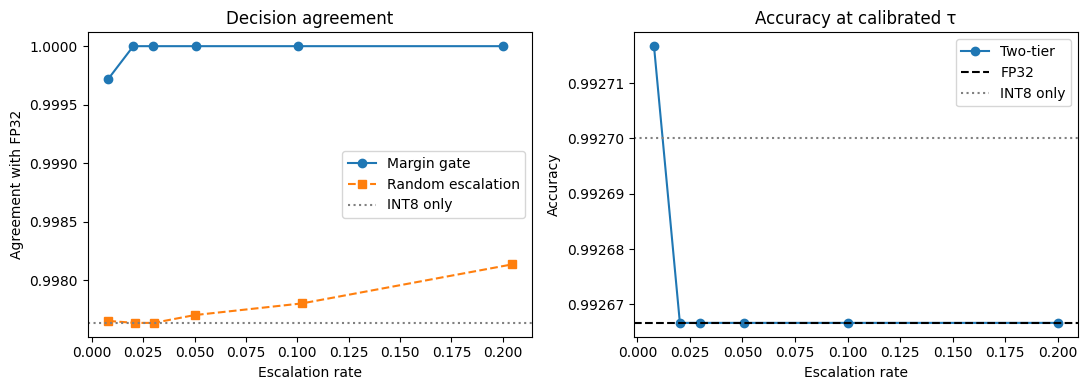

Saved to /content/drive/MyDrive/CS228/results


In [29]:
# ---------------- save + plot ----------------
mean.to_csv(OUT_DIR / "summary_mean.csv"); std.to_csv(OUT_DIR / "summary_std.csv"); df.to_csv(OUT_DIR / "all_splits.csv", index=False)
json.dump(dict(far_target=FAR_TARGET, budgets=BUDGETS, n_pairs=int(len(labels)), n_splits=N_SPLITS,
               c1_ms=c1, c2_ms=c2, latency=lat, int8_mb=mb(INT8_PATH), fp32_mb=mb(FP32_PATH),
               auc_fp32=float(roc_auc_score(labels, s_fp32)), auc_int8=float(roc_auc_score(labels, s_int8)),
               cpu=platform.processor(), ort=ort.__version__), open(OUT_DIR / "meta.json", "w"), indent=2)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
m = mean.loc[[i for i in mean.index if i.startswith("Two-tier (margin)")]]
r = mean.loc[[i for i in mean.index if i.startswith("Random")]]
ax[0].plot(m.escalation, m.agreement_FP32, "o-", label="Margin gate")
ax[0].plot(r.escalation, r.agreement_FP32, "s--", label="Random escalation")
ax[0].axhline(mean.loc["INT8 only", "agreement_FP32"], color="gray", ls=":", label="INT8 only")
ax[0].set_xlabel("Escalation rate"); ax[0].set_ylabel("Agreement with FP32"); ax[0].legend(); ax[0].set_title("Decision agreement")
ax[1].plot(m.escalation, m.accuracy, "o-", label="Two-tier")
ax[1].axhline(mean.loc["FP32 (reference)", "accuracy"], color="k", ls="--", label="FP32")
ax[1].axhline(mean.loc["INT8 only", "accuracy"], color="gray", ls=":", label="INT8 only")
ax[1].set_xlabel("Escalation rate"); ax[1].set_ylabel("Accuracy"); ax[1].legend(); ax[1].set_title("Accuracy at calibrated τ")
plt.tight_layout(); plt.savefig(OUT_DIR / "agreement_vs_escalation.png", dpi=150); plt.show()
print("Saved to", OUT_DIR.resolve())